In [1]:
import pandas as pd
from datetime import datetime
import os
import plotly.express as px
import plotly.graph_objects as go

In [2]:
# Load the CSV file into a pandas DataFrame
cPath = os.path.dirname(os.path.realpath('./New/'))
file_path = cPath + '/Combined_Terminal_Label.csv'
print(file_path)
myData = pd.read_csv(file_path, parse_dates=['DateTime'], date_format='%Y-%m-%d %H:%M:%S')
myData.set_index('DateTime', drop = False, inplace=True)
# print(myData.head)
print(myData.index.name)

/home/homayoun/Dropbox/Projects/VisualCode/Python/CAE/New/KWH_based/Combined_Terminal_Label.csv
DateTime


In [3]:
# Find electricity usage data
# We already havet this information. I am using it to check my calculations. They should be the same as in the spreadsheet.

def monthlyUsage(data, mstart, mend):
    usage = []
    etimestamp = pd.date_range(start=mstart, end=mend, freq='ME')
    stimestamp = pd.date_range(start=mstart, end=mend, freq='MS')
    sum = 0
    for i in range(0, len(etimestamp)):
        # Use boolean masking instead of loc to avoid DST issues
        mask = (data.index >= stimestamp[i]) & (data.index <= etimestamp[i])
        month = data[mask]
        month_sum = month['KWH11'].sum()
        sum += month_sum
        usage.append(float(month_sum))
    print('In the function: ', sum)
    return usage
        
    
Y23_Usage = monthlyUsage(myData, '2023-01-01', '2023-12-31')
print(Y23_Usage)
#print(myData['KWH11'].sum())

In the function:  6938824.0
[517804.5, 484157.5, 554941.5, 550419.5, 602324.5, 525710.5, 698522.0, 737059.5, 640602.5, 556467.5, 522408.5, 548406.0]


In [4]:
# This portion needs to be inspected carefully for correct calculations.
def rprt(data, start, end):
    # Calculate the total usage for each year in units of KWh in increments of 15 minutes
    data = data.loc[start:end]
    soffpeak = data[data['label'] == 'sOffPeak']['KWH11'].sum()
    woffpeak = data[data['label'] == 'wOffPeak']['KWH11'].sum()
    wkndoffpeak = data[data['label'] == 'wkndOffPeak']['KWH11'].sum()
    wonpeak = data[data['label'] == 'wOnPeak']['KWH11'].sum()
    sonpeak = data[data['label'] == 'sOnPeak']['KWH11'].sum()
    wonpeakhigh = data[data['label'] == 'wOnPeakHigh']['KWH11'].sum()
    sonpeakhigh = data[data['label'] == 'sOnPeakHigh']['KWH11'].sum()

    # Calculate the average usage for each year in units of Wh in increments of 15 minutes during the On Peak hours 
    # This is a rough calculation and needs to be further refined based month, time, and holidays
    print(data['KWH11'].sum())
    print('wOffPeak:', woffpeak)
    print('sOffPeak:', soffpeak)
    print('wkndOffPeak:', wkndoffpeak)
    print('wOnPeak:', wonpeak)
    print('sOnPeak:', sonpeak)
    print('wOnPeakHigh:', wonpeakhigh)
    print('sOnPeakHigh:', sonpeakhigh)
    print('Total offpeak', soffpeak + woffpeak + wkndoffpeak)
    print('Total onpeak: ', wonpeak + soffpeak+wonpeakhigh+sonpeakhigh)
    print('Total:', ((soffpeak+woffpeak+wkndoffpeak)*0.04458 + wonpeak*0.08911 + sonpeak*0.08911 + wonpeakhigh * 0.08911 + sonpeakhigh*0.08911)/4)
    print('Modified Total:', ((soffpeak+woffpeak+wkndoffpeak)*0.057400 + wonpeak*0.068340 + wonpeakhigh * 0.068340)/4 + 1750 + 13451.56 + 962.22)
    print()

myData = myData.sort_index()
rprt(myData, '2023-12-28', '2024-01-29')


597932.0
wOffPeak: 244008.0
sOffPeak: 0.0
wkndOffPeak: 180306.0
wOnPeak: 156521.0
sOnPeak: 0.0
wOnPeakHigh: 17097.0
sOnPeakHigh: 0.0
Total offpeak 424314.0
Total onpeak:  173618.0
Total: 8596.754525
Modified Total: 25218.94943



In [5]:
data = myData.loc['2023-01-01':'2023-12-31']
#data = myData.loc['2023-08-01':'2023-08-30']
#label_mask = (data['label'] == 'sOnPeakHigh') | (data['label'] == 'sOnPeak') | (data['label'] == 'OffPeak')
label_mask = (data['label'] == 'sOnPeakHigh') | (data['label'] == 'sOnPeak')
month_mask = data.index.month.isin([5, 6, 7, 8, 9])
print(data.loc[month_mask & label_mask]['KW'].max())
print(data.loc[month_mask & label_mask]['KW'].idxmax())
#print(data.loc[month_mask & label_mask]['KW'])
print(data[data['KW'] == 1308])

1698
2023-08-14 21:44:00
                               DateTime  KWH11    KW  Year     Delta  \
DateTime                                                               
2023-04-12 13:29:00 2023-04-12 13:29:00  327.0  1308  2023  0.009444   
2023-04-27 13:59:00 2023-04-27 13:59:00  327.0  1308  2023 -0.000556   
2023-05-14 21:59:00 2023-05-14 21:59:00  327.0  1308  2023 -0.037778   
2023-05-20 00:44:00 2023-05-20 00:44:00  327.0  1308  2023 -0.001111   
2023-06-15 16:44:00 2023-06-15 16:44:00  327.0  1308  2023 -0.004444   
2023-07-28 04:44:00 2023-07-28 04:44:00  327.0  1308  2023  0.018889   
2023-07-28 05:44:00 2023-07-28 05:44:00  327.0  1308  2023 -0.052778   
2023-08-18 03:14:00 2023-08-18 03:14:00  327.0  1308  2023  0.003333   
2023-08-19 02:44:00 2023-08-19 02:44:00  327.0  1308  2023 -0.002222   
2023-09-05 03:14:00 2023-09-05 03:14:00  327.0  1308  2023  0.008889   
2023-09-15 21:29:00 2023-09-15 21:29:00  327.0  1308  2023  0.013889   
2023-09-17 21:29:00 2023-09-17 21:29:00

<bound method NDFrame.head of DateTime
2023-06-01 00:00:00    5074
2023-06-01 01:00:00    4958
2023-06-01 02:00:00    4062
2023-06-01 03:00:00    3960
2023-06-01 04:00:00    4210
                       ... 
2023-06-30 19:00:00    3312
2023-06-30 20:00:00    2880
2023-06-30 21:00:00    4340
2023-06-30 22:00:00    4380
2023-06-30 23:00:00    4402
Freq: h, Name: KW, Length: 720, dtype: int64>


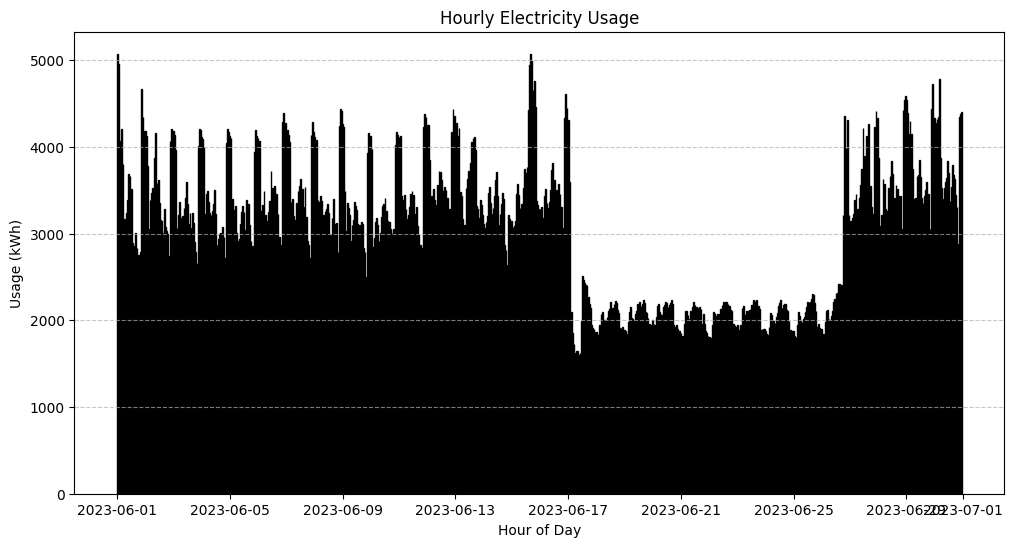

In [10]:
data = myData.loc['2023-06-01':'2023-06-30']
hourly = data['KW'].resample('h').sum()
print(hourly.head)

import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.bar(hourly.index, hourly, width=0.03, color='skyblue', edgecolor='black')

plt.title("Hourly Electricity Usage")
plt.xlabel("Hour of Day")
plt.ylabel("Usage (kWh)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()
iYear = 2024
fig = px.area(
    hourly,
    #x='DateTime', 
    #y='KWH11', 
    title=f'Categorized Electricity Usage in {iYear} (KWh)'
    )
fig.show()

In [7]:
# Get the data corresponding to the same invoice period (April invoice)
data = myData.loc['2024-02-28':'2024-03-27']
# Isolate the on-peak periods (Winter)
label_mask = (data['label'] == 'wOnPeakHigh') | (data['label'] == 'wOnPeak')
print(data.loc[label_mask]['KWH11'].max())
print(data.loc[label_mask]['KWH11'].idxmax())
print(data.loc[label_mask]['KWH11'].sum())
label_mask = (data['label'] == 'wOffPeak')
print(data.loc[label_mask]['KWH11'].max())
print(data.loc[label_mask]['KWH11'].idxmax())
print(data.loc[label_mask]['KWH11'].sum())

269.0
2024-03-25 21:59:00
166811.0
296.0
2024-03-07 12:44:00
223024.5
